# Referencias y umbral de medición

Este cuaderno fija el **umbral de medición**: el error de los modelos de referencia, que cualquier modelo de consumo tiene que mejorar para aportar algo. Las reglas de evaluación (origen, horizonte, pliegues, métricas y segmentos) están en `docs/modelado/decisiones.md`, y las referencias, en `src/models/baselines.py` y `src/models/energy_baselines.py`.

Todo se calcula en el pliegue de **validación**: se pronostica cada día de 2011-2012 desde las 00:00 hora local, y la escala del MASE y la climatología salen de 2010-2011. El año de test, 2012-2013, no se mira aquí. Sus cifras se calcularán una sola vez, junto con el primer LightGBM.

Las tablas se generan antes, desde la raíz del proyecto, con

```
python -m src.models.baselines
```

que las guarda en `data/results/`. El cuaderno solo las lee. Tiene cinco bloques:

- **1. Error frente al horizonte**: MASE por día de horizonte y por hora del día, y error de la energía diaria.
- **2. Media frente a mediana**: el sesgo que introduce predecir la mediana.
- **3. Dónde fallan las referencias**: tipo de día, estación, Navidad, calor y casa vacía.
- **4. Semanas y meses**: energía de bloques de 7 y 28 días según la antelación.
- **5. El umbral**: las cifras que tiene que mejorar cada modelo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
results_dir = project_root / "data" / "results"
FOLD = "validacion"


def load(table):
    path = results_dir / f"referencias_{FOLD}_{table}.parquet"
    if not path.is_file():
        raise FileNotFoundError(f"No se encontró {path}. Ejecutar antes: python -m src.models.baselines")
    return pd.read_parquet(path)


by_step = load("por_paso").set_index(["modelo", "paso"])
by_day = load("por_dia").set_index(["modelo", "dia"])
by_hour = load("por_hora").set_index(["modelo", "hora_local"])
by_band = load("noche").set_index(["modelo", "franja"])
energy = load("energia_diaria").set_index(["modelo", "dia"])
by_segment = load("por_segmento").set_index(["modelo", "segmento", "valor"]).sort_index()
blocks = load("bloques").set_index(["bloque", "antelacion", "referencia"]).sort_index()

MODELS = ["media_7_dias", "mediana_7_dias", "persistencia_24h", "persistencia_168h", "climatologia"]
NAMES = {"media_7_dias": "media de 7 días", "mediana_7_dias": "mediana de 7 días",
         "persistencia_24h": "persistencia de 24 h", "persistencia_168h": "persistencia de 168 h",
         "climatologia": "climatología"}
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 250)

# Estilo de los gráficos, el mismo de forecasting_eda.ipynb
SURFACE = "#fcfcfb"
TEXT = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID = "#e4e3de"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
YELLOW = "#eda100"
MAGENTA = "#e87ba4"
COLORS = dict(zip(MODELS, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "figure.dpi": 100,
    "font.size": 9.5,
    "text.color": TEXT,
    "axes.titlecolor": TEXT,
    "axes.titlesize": 10.5,
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.edgecolor": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "lines.linewidth": 1.6,
    "legend.frameon": False,
})


def by_model(series, digits=3):
    """Una columna por referencia, en el orden de MODELS, a partir de una Series con nivel modelo."""
    return series.unstack("modelo")[MODELS].rename(columns=NAMES).round(digits)


def label_line_ends(ax, x, ends, min_gap):
    """Etiqueta el final de cada línea; separa verticalmente las etiquetas que quedarían encima unas de otras."""
    placed = []
    for label, y in sorted(ends.items(), key=lambda item: item[1]):
        position = max(y, placed[-1] + min_gap) if placed else y
        placed.append(position)
        ax.annotate(label, (x, y), xytext=(x, position), textcoords="data", color=TEXT_SECONDARY,
                    fontsize=8.5, va="center", annotation_clip=False)

## 1. Error frente al horizonte

### 1.1 MASE por día de horizonte y por hora del día

El MASE de cada hogar es su error absoluto medio dividido por su escala: el error que tenía, en 2010-2011, copiar la hora de 24 horas antes. Un MASE de 1 es, por tanto, el error de copiar el día anterior en el año de ajuste. Se resume con la mediana de los 300 hogares. El día de horizonte 1 es el día del origen, de 00:00 a 24:00; el 14, trece días después.

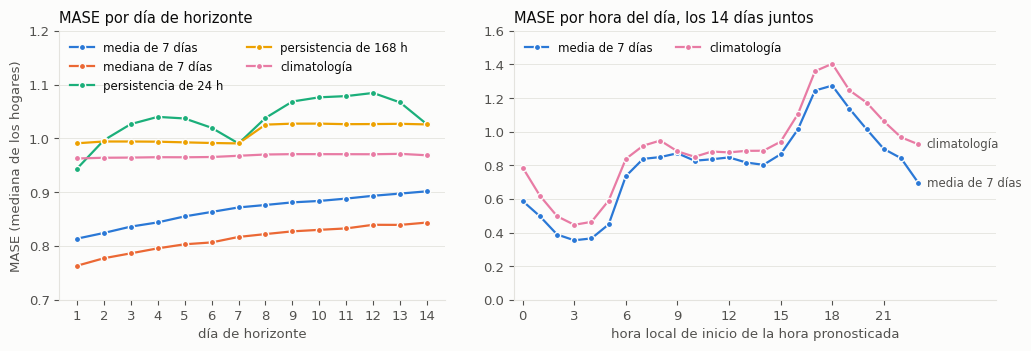

MASE por día de horizonte (mediana de los hogares):


dia,1,2,3,4,5,6,7,8,9,10,11,12,13,14
modelo,,,,,,,,,,,,,,
media de 7 días,0.814,0.824,0.836,0.844,0.855,0.863,0.872,0.876,0.881,0.884,0.888,0.893,0.897,0.902
mediana de 7 días,0.763,0.777,0.786,0.796,0.803,0.807,0.817,0.822,0.827,0.830,0.833,0.839,0.839,0.844
persistencia de 24 h,0.944,0.997,1.027,1.040,1.037,1.020,0.991,1.038,1.069,1.076,1.079,1.085,1.067,1.026
persistencia de 168 h,0.991,0.994,0.994,0.994,0.993,0.991,0.991,1.026,1.027,1.027,1.026,1.027,1.027,1.026
climatología,0.963,0.964,0.964,0.965,0.965,0.965,0.968,0.970,0.971,0.971,0.971,0.971,0.971,0.969


MASE por hora local de la hora pronosticada (mediana de los hogares):


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
modelo,,,,,,,,,,,,,,,,,,,,,,,,
media de 7 días,0.59,0.50,0.39,0.35,0.36,0.45,0.74,0.84,0.85,0.87,0.83,0.84,0.85,0.82,0.80,0.87,1.01,1.24,1.27,1.14,1.01,0.90,0.84,0.70
mediana de 7 días,0.53,0.43,0.34,0.31,0.33,0.39,0.68,0.82,0.80,0.82,0.75,0.76,0.76,0.74,0.73,0.79,0.93,1.19,1.25,1.11,0.97,0.87,0.79,0.65
persistencia de 24 h,0.67,0.58,0.44,0.39,0.42,0.51,0.86,0.99,1.03,1.07,0.99,1.01,1.02,0.98,0.98,1.06,1.22,1.53,1.57,1.40,1.23,1.07,1.00,0.80
persistencia de 168 h,0.69,0.58,0.45,0.41,0.43,0.51,0.84,0.96,0.98,1.00,0.92,0.99,0.97,0.96,0.95,1.02,1.20,1.49,1.52,1.36,1.22,1.09,1.00,0.82
climatología,0.79,0.62,0.50,0.45,0.46,0.59,0.84,0.92,0.95,0.88,0.85,0.88,0.88,0.89,0.89,0.94,1.10,1.36,1.40,1.25,1.17,1.06,0.97,0.93


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1, 1.25]})

ax = axes[0]
mase_day = by_day["mase_mediana"].unstack("modelo")[MODELS]
for model in MODELS:
    ax.plot(mase_day.index, mase_day[model], color=COLORS[model], marker="o", markersize=4.5,
            markeredgecolor=SURFACE, markeredgewidth=1, label=NAMES[model])
ax.set_xticks(range(1, 15))
ax.set_xlabel("día de horizonte")
ax.set_ylabel("MASE (mediana de los hogares)")
ax.set_title("MASE por día de horizonte", loc="left")
ax.legend(loc="upper left", ncols=2, fontsize=8.5)
ax.set_ylim(0.7, 1.2)

ax = axes[1]
hour_models = ["media_7_dias", "climatologia"]
mase_hour = by_hour["mase_mediana"].unstack("modelo")[hour_models]
for model in hour_models:
    ax.plot(mase_hour.index, mase_hour[model], color=COLORS[model], marker="o", markersize=4.5,
            markeredgecolor=SURFACE, markeredgewidth=1, label=NAMES[model])
label_line_ends(ax, 23.5, {NAMES[m]: mase_hour[m].iloc[-1] for m in hour_models}, 0.08)
ax.set_xticks(range(0, 24, 3))
ax.set_xlim(-0.5, 27.5)
ax.set_ylim(0, 1.6)
ax.set_xlabel("hora local de inicio de la hora pronosticada")
ax.set_title("MASE por hora del día, los 14 días juntos", loc="left")
ax.legend(loc="upper left", ncols=2, fontsize=8.5)
fig.tight_layout()
plt.show()

print("MASE por día de horizonte (mediana de los hogares):")
display(by_model(by_day["mase_mediana"]).T)
print("MASE por hora local de la hora pronosticada (mediana de los hogares):")
display(by_model(by_hour["mase_mediana"], 2).T)

**Resultado.** La media de 7 días es la mejor referencia sin sesgo en los 14 días. Su MASE va de 0,81 el día del origen a 0,90 trece días después, siempre por debajo de 1. La mediana de 7 días tiene aún menos error (de 0,76 a 0,84), pero a costa de un sesgo que se ve en la sección 2. Las dos empeoran despacio con el horizonte, porque el consumo de la última semana sigue siendo informativo dos semanas después (sección 4.3 del análisis exploratorio).

Copiar un solo día o una sola semana da bastante más error. La persistencia de 24 horas solo compite el día 1 (0,94). Desde el día 2 está por encima de 1 y de la climatología, salvo los días 7 y 14, que caen en el mismo día de la semana que el día copiado. La persistencia de 168 horas se queda en 0,99 la primera semana y en 1,03 la segunda. La climatología, que no usa el pasado reciente, está plana entre 0,96 y 0,97. Es el error al que convergerían las demás si el pasado dejara de servir, y a 14 días la media de 7 días sigue claramente por debajo.

El error depende mucho más de la hora del día que del horizonte. Con la media de 7 días, el MASE va de 0,35 a las 03:00 a 1,27 a las 18:00: de madrugada el consumo es bajo y regular, y en el pico de la tarde, alto y variable. Las cinco referencias siguen el mismo ciclo, que se repite en cada día de horizonte (la tabla por paso está en `referencias_validacion_por_paso.parquet`).

### 1.2 Error de la energía diaria

La batería suma horas, así que lo que importa para la autonomía es la energía del día. Para cada origen y día de horizonte se compara la energía pronosticada con la real, en % de la energía diaria media del hogar en 2010-2011. Se da la mediana entre hogares del error absoluto medio de cada uno y el sesgo de todos los días juntos.

In [3]:
print("Error de la energía diaria (% de la energía diaria media del hogar, mediana de los hogares):")
display(by_model(energy["error_energia_mediana"], 1).T)
print("Sesgo de la energía diaria, todos los días juntos (%):")
display(by_model(energy["sesgo_energia_total"], 1).T)

Error de la energía diaria (% de la energía diaria media del hogar, mediana de los hogares):


dia,1,2,3,4,5,6,7,8,9,10,11,12,13,14
modelo,,,,,,,,,,,,,,
media de 7 días,18.4,19.2,19.8,20.2,20.6,21.0,21.2,21.6,21.8,22.1,22.3,22.6,22.7,22.8
mediana de 7 días,19.5,20.5,21.0,21.3,21.6,22.0,22.4,22.8,23.5,23.8,24.0,24.1,24.1,24.2
persistencia de 24 h,19.6,22.0,23.6,24.3,24.8,24.5,24.0,25.6,26.3,26.4,26.7,26.9,27.0,26.0
persistencia de 168 h,24.0,24.1,24.0,24.0,24.0,24.0,24.0,26.1,26.1,26.1,26.0,26.0,26.0,26.0
climatología,26.4,26.4,26.4,26.4,26.4,26.4,26.5,26.6,26.6,26.6,26.6,26.5,26.5,26.4


Sesgo de la energía diaria, todos los días juntos (%):


dia,1,2,3,4,5,6,7,8,9,10,11,12,13,14
modelo,,,,,,,,,,,,,,
media de 7 días,0.0,0.0,0.0,0.0,-0.0,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,0.1
mediana de 7 días,-11.8,-11.8,-11.8,-11.8,-11.8,-11.9,-11.9,-11.9,-11.9,-11.9,-11.9,-11.9,-11.9,-11.8
persistencia de 24 h,-0.0,0.0,0.0,-0.0,-0.1,-0.1,-0.1,-0.2,-0.2,-0.1,-0.1,-0.1,-0.1,0.0
persistencia de 168 h,0.0,0.1,0.1,0.0,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,-0.1,0.0
climatología,6.3,6.4,6.4,6.3,6.3,6.3,6.2,6.2,6.2,6.2,6.2,6.2,6.3,6.4


**Resultado.** En la energía diaria el orden es el mismo. Con la media de 7 días, el error de la energía de un día es del 18,4 % de la energía diaria media del hogar el día del origen y del 22,8 % trece días después, sin sesgo. La mediana de 7 días, que tenía menos MASE, tiene aquí más error que la media (del 19,5 al 24,2 %), porque subestima la energía de todos los días un 11,8 %. La climatología se queda en el 26,4 %, con un sesgo de +6,3 %. Se ajusta con 2010-2011, y en 2011-2012 los hogares consumieron algo menos (sección 2.6 del análisis exploratorio) y el verano fue más fresco (sección 3.3).

## 2. Media frente a mediana

La sección 1.5 del análisis exploratorio mostró que, incluso conociendo el hogar y el calendario, la media del consumo es claramente mayor que la mediana, y la pregunta 3 dejó abierto qué predecir. Las dos referencias de 7 días permiten verlo con pronósticos: usan las mismas 7 horas y solo cambia el estadístico. Se compara su sesgo según la franja y la hora del día.

Sesgo de todas las horas juntas, por franja (%):


modelo,media de 7 días,mediana de 7 días
franja,,
de 06:00 a 18:00,-0.1,-15.6
de 18:00 a 06:00,0.0,-8.5


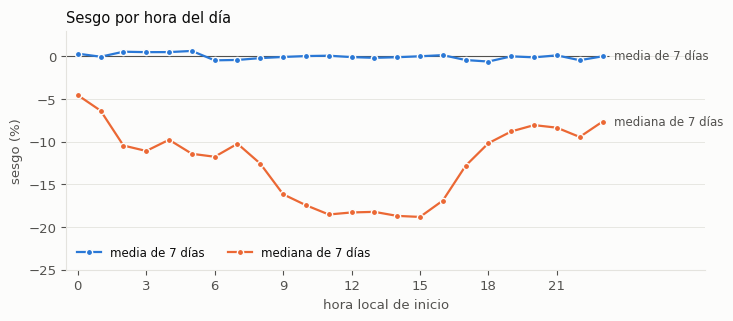

Sesgo por hora local (%):


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
modelo,,,,,,,,,,,,,,,,,,,,,,,,
media de 7 días,0.3,-0.0,0.6,0.5,0.5,0.6,-0.5,-0.4,-0.2,-0.1,0.0,0.1,-0.1,-0.2,-0.1,0.0,0.2,-0.4,-0.6,0.0,-0.1,0.1,-0.4,0.0
mediana de 7 días,-4.5,-6.4,-10.4,-11.1,-9.8,-11.4,-11.8,-10.2,-12.6,-16.2,-17.4,-18.5,-18.3,-18.2,-18.7,-18.8,-16.9,-12.8,-10.2,-8.8,-8.1,-8.4,-9.4,-7.6


Día 1: MAE de todas las horas juntas (kWh), MASE y sesgo (%):


,mae_kwh,mase_mediana,sesgo_total
modelo,,,
media de 7 días,0.331,0.814,0.013
mediana de 7 días,0.309,0.763,-11.794


In [4]:
pair = ["media_7_dias", "mediana_7_dias"]
print("Sesgo de todas las horas juntas, por franja (%):")
display(by_model(by_band["sesgo_total"], 1)[[NAMES[m] for m in pair]])

bias_hour = by_hour["sesgo_total"].unstack("modelo")[pair]
fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.hlines(0, -0.5, 23.3, color=TEXT_SECONDARY, linewidth=0.8)
for model in pair:
    ax.plot(bias_hour.index, bias_hour[model], color=COLORS[model], marker="o", markersize=4.5,
            markeredgecolor=SURFACE, markeredgewidth=1, label=NAMES[model])
label_line_ends(ax, 23.5, {NAMES[m]: bias_hour[m].iloc[-1] for m in pair}, 2)
ax.set_xticks(range(0, 24, 3))
ax.set_xlim(-0.5, 27.5)
ax.set_ylim(-25, 3)
ax.set_xlabel("hora local de inicio")
ax.set_ylabel("sesgo (%)")
ax.set_title("Sesgo por hora del día", loc="left")
ax.legend(loc="lower left", ncols=2, fontsize=8.5)
fig.tight_layout()
plt.show()

print("Sesgo por hora local (%):")
display(bias_hour.rename(columns=NAMES).round(1).T)
print("Día 1: MAE de todas las horas juntas (kWh), MASE y sesgo (%):")
display(by_day.xs(1, level="dia").loc[pair, ["mae_kwh", "mase_mediana", "sesgo_total"]].rename(index=NAMES).round(3))

**Resultado.** Predecir la mediana subestima el consumo a todas las horas. La mediana de 7 días queda un 15,6 % por debajo del consumo real entre las 06:00 y las 18:00 y un 8,5 % entre las 18:00 y las 06:00. La media de 7 días no tiene sesgo en ninguna hora: siempre está a menos de un 1 %. El sesgo de la mediana es mayor a mediodía, entre el −17 y el −19 % de las 10:00 a las 15:00, cuando el consumo de cada día es más irregular, y menor a medianoche (−4,5 % a las 00:00).

A cambio, la mediana tiene menos error absoluto: 0,309 kWh frente a 0,331 el día 1. Es lo que anticipaba la pregunta 3 del análisis exploratorio. El MAE premia predecir la mediana, pero la batería suma horas, y sumar medianas da menos energía de la real. Un modelo entrenado con pérdida L1 haría lo mismo y daría una autonomía mayor que la real. Por eso el umbral se fija con la media de 7 días y el sesgo es una métrica obligatoria (sección 5).

## 3. Dónde fallan las referencias

Cada hora se asigna a un segmento según el día local en que cae: tipo de día, estación, Navidad (del 23 de diciembre al 6 de enero), calor (máxima de 30 °C o más) y casa vacía (marca de `src/features/vacancy.py`). Las tablas recogen todos los días de horizonte juntos.

In [5]:
order = [("tipo_dia", "laborable"), ("tipo_dia", "sábado"), ("tipo_dia", "domingo"), ("tipo_dia", "festivo"),
         ("estacion", "verano"), ("estacion", "otoño"), ("estacion", "invierno"), ("estacion", "primavera"),
         ("navidad", "sí"), ("calor", "sí"), ("casa_vacia", "sí")]
mase_segment = by_model(by_segment["mase_mediana"]).loc[order]
bias_segment = by_model(by_segment["sesgo_total"], 1).loc[order]
hours_media = by_segment.loc["media_7_dias", "horas"]
share = (100 * hours_media.loc[order] / hours_media.loc["tipo_dia"].sum()).round(1)
print("MASE por segmento (mediana de los hogares) y % de las horas evaluadas que caen en él:")
display(mase_segment.assign(**{"% de las horas": share.to_numpy()}))
print("Sesgo por segmento, todas las horas juntas (%):")
display(bias_segment)
print("Hogares con días de casa vacía en el año de validación:",
      int(by_segment.loc[("media_7_dias", "casa_vacia", "sí"), "hogares"]))

MASE por segmento (mediana de los hogares) y % de las horas evaluadas que caen en él:


modelo                media de 7 días  mediana de 7 días  persistencia de 24 h  persistencia de 168 h  climatología  % de las horas
segmento   valor                                                                                                                   
tipo_dia   laborable            0.833              0.773                 1.002                  0.965         0.940            68.9
           sábado               0.904              0.864                 1.075                  1.074         1.021            14.0
           domingo              0.932              0.900                 1.113                  1.100         1.016            13.4
           festivo              0.844              0.810                 0.973                  1.000         0.965             3.7
estacion   verano               0.720              0.669                 0.871                  0.859         0.853            25.8
           otoño                0.773              0.724                 0.927                  0.895         0.891            26.1
           invierno             1.136              1.084                 1.362                  1.313         1.231            22.4
           primavera            0.810              0.754                 0.973                  0.949         0.851            25.8
navidad    sí                   0.761              0.726                 0.915                  0.903         0.920             4.2
calor      sí                   0.823              0.786                 0.981                  0.951         0.937             3.4
casa_vacia sí                   0.855              0.679                 0.800                  0.939         1.455             1.2

Sesgo por segmento, todas las horas juntas (%):


modelo                media de 7 días  mediana de 7 días  persistencia de 24 h  persistencia de 168 h  climatología
segmento   valor                                                                                                   
tipo_dia   laborable              1.5              -10.5                   1.5                    0.3           6.4
           sábado                -1.2              -12.9                  -1.2                   -0.2           7.5
           domingo               -4.7              -16.0                  -4.7                    0.0           3.3
           festivo               -6.8              -17.4                  -6.0                   -6.0           9.7
estacion   verano                 0.2              -12.1                   0.0                    0.2          16.0
           otoño                 -2.7              -14.0                  -1.8                   -2.7           5.2
           invierno               0.5              -10.7                   0.5                    0.6           3.3
           primavera              1.7              -10.7                   1.0                    1.7           1.5
navidad    sí                    -2.2              -13.9                  -1.6                   -2.9          17.7
calor      sí                   -14.9              -25.2                 -14.7                  -16.4          -8.1
casa_vacia sí                   101.0               71.2                  78.4                  102.5         279.9

Hogares con días de casa vacía en el año de validación: 58


**Resultado.** Las cinco referencias fallan en los mismos sitios. Se comenta la media de 7 días.

- **Estación.** El invierno es la estación más difícil, con un MASE de 1,14 frente a 0,72 en verano. En invierno el consumo es mayor y más variable, sobre todo en el pico de la tarde (sección 3.3 del análisis exploratorio), y la escala del MASE es la de todo el año.
- **Tipo de día.** Los fines de semana tienen más error que los laborables (0,90 el sábado y 0,93 el domingo, frente a 0,83). Los domingos y los festivos salen subestimados (−4,7 y −6,8 %), porque los 7 días anteriores incluyen cinco laborables, que consumen menos (sección 3.1).
- **Calor.** En los días de 30 °C o más, las referencias que copian el pasado reciente subestiman en torno a un 15 % (la media de 7 días, un 14,9 %). El pasado reciente no anticipa el aire acondicionado de un día caluroso (sección 5.3).
- **Casa vacía.** En los 58 hogares con días de casa vacía en 2011-2012, esos días se sobrestiman al doble (+101 %): el pasado no sabe que la casa se ha quedado vacía. Su MASE no es alto porque el consumo, y con él el error en kWh, es bajo.
- **Navidad.** Error algo menor que el resto del año (0,76), con un sesgo pequeño (−2,2 %).

Lo que estas referencias no pueden hacer, y un modelo con calendario y temperatura sí, es anticipar los domingos, los festivos y los días de calor.

## 4. Semanas y meses

El encargo pide responder también a semanas y meses (Plan, sección 1). A esos plazos el pronóstico ya no se refiere a horas concretas, sino a la energía de un periodo, y se hará con un modelo aparte (decisiones.md, sección 8). Aquí se fija su umbral con dos referencias para la energía de un bloque de días seguidos: 7 días (una semana) o 28 días (cuatro semanas, el "mes"), que contienen siempre los mismos días de la semana.

- **reciente**: la energía diaria media de los 7 días anteriores al origen, por la longitud del bloque.
- **año anterior**: la energía del mismo bloque 364 días antes. No depende de la antelación.

La **antelación** son los días entre el origen y el inicio del bloque: 0 si el bloque empieza el día del origen, 28 si empieza cuatro semanas después. Cada bloque del año de validación se pronostica con cada antelación, así que todas las antelaciones se miden sobre los mismos bloques. El error está en % de la energía media de un bloque del hogar en 2010-2011.

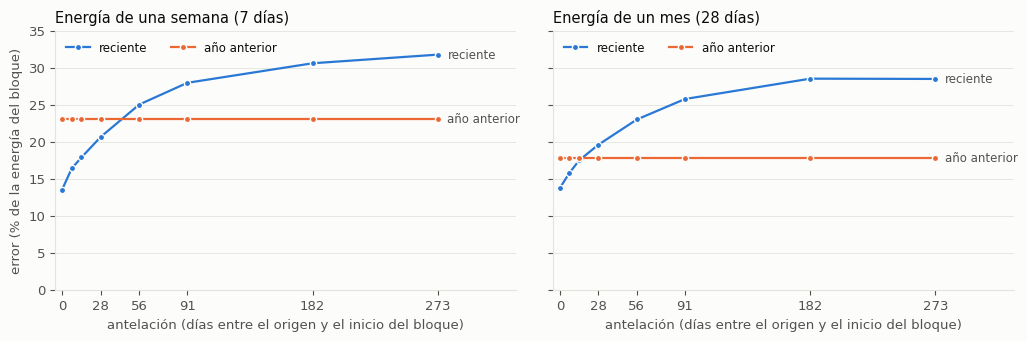

Bloques de 7 días: error y sesgo (%), mediana de los hogares y total:


error_mediana          sesgo_mediana           sesgo_total         
referencia  año_anterior reciente  año_anterior reciente año_anterior reciente
antelacion                                                                    
0                   23.1     13.5           4.4     -0.1          6.0     -0.2
7                   23.1     16.4           4.4     -0.1          6.0     -0.1
14                  23.1     17.9           4.4     -0.1          6.0     -0.1
28                  23.1     20.7           4.4     -0.1          6.0      0.1
56                  23.1     25.0           4.4      0.6          6.0      1.0
91                  23.1     28.0           4.4      1.0          6.0      1.5
182                 23.1     30.6           4.4      3.8          6.0      4.9
273                 23.1     31.8           4.4      4.0          6.0      5.1

Bloques de 28 días: error y sesgo (%), mediana de los hogares y total:


error_mediana          sesgo_mediana           sesgo_total         
referencia  año_anterior reciente  año_anterior reciente año_anterior reciente
antelacion                                                                    
0                   17.8     13.7           4.9      0.1          6.5      0.2
7                   17.8     15.8           4.9      0.2          6.5      0.5
14                  17.8     17.5           4.9      0.6          6.5      0.9
28                  17.8     19.6           4.9      1.4          6.5      2.1
56                  17.8     23.0           4.9      3.1          6.5      4.0
91                  17.8     25.8           4.9      3.5          6.5      4.5
182                 17.8     28.5           4.9      6.4          6.5      8.2
273                 17.8     28.5           4.9      6.4          6.5      7.9

In [6]:
REFS = {"reciente": BLUE, "año_anterior": ORANGE}
REF_NAMES = {"reciente": "reciente", "año_anterior": "año anterior"}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5), sharey=True)
for ax, (block, title) in zip(axes, [("semana", "Energía de una semana (7 días)"), ("mes", "Energía de un mes (28 días)")]):
    table = blocks.loc[block, "error_mediana"].unstack("referencia")
    for reference, color in REFS.items():
        ax.plot(table.index, table[reference], color=color, marker="o", markersize=4.5,
                markeredgecolor=SURFACE, markeredgewidth=1, label=REF_NAMES[reference])
    label_line_ends(ax, 280, {REF_NAMES[r]: table[r].iloc[-1] for r in REFS}, 1.5)
    ax.set_xticks([0, 28, 56, 91, 182, 273])
    ax.set_xlim(-5, 330)
    ax.set_xlabel("antelación (días entre el origen y el inicio del bloque)")
    ax.set_title(title, loc="left")
    ax.legend(loc="upper left", ncols=2, fontsize=8.5)
axes[0].set_ylabel("error (% de la energía del bloque)")
axes[0].set_ylim(0, 35)
fig.tight_layout()
plt.show()

columns = ["error_mediana", "sesgo_mediana", "sesgo_total"]
for block in ["semana", "mes"]:
    print(f"Bloques de {'7' if block == 'semana' else '28'} días: error y sesgo (%), mediana de los hogares y total:")
    display(blocks.loc[block, columns].unstack("referencia").round(1))

**Resultado.** Con poca antelación, el pasado reciente es la mejor referencia. Si el bloque empieza el día del origen, la referencia reciente se equivoca en un 13,5 % de la energía de una semana y en un 13,7 % de la de un mes, sin sesgo. Su error crece con la antelación: a 28 días es del 20,7 % en la semana y del 19,6 % en el mes, y a 91 días, del 28 y el 26 %.

El año anterior no depende de la antelación: 23,1 % en la semana y 17,8 % en el mes. En el mes el error es menor porque, al sumar 28 días, los días raros se compensan. Por eso el cruce llega antes en el mes. La referencia reciente deja de ser la mejor entre los 28 y los 56 días de antelación en la semana, como los 43 días que encontró el análisis exploratorio (sección 4.4), y entre los 14 y los 28 días en el mes.

El año anterior tiene un sesgo de +6 % en la semana y de +6,5 % en el mes: sobrestima porque en 2011-2012 se consumió algo menos que en 2010-2011. Con un solo año de historia, todo lo que cambia de un año a otro entra en su error, como el nivel de algunos hogares o un verano más fresco. En el test, con dos años de historia, se podrán promediar los dos años anteriores.

Responder a cuánto se consumirá dentro de uno o varios meses no es, por tanto, un problema del modelo horario. Hace falta un modelo de la energía del periodo que combine el nivel reciente del hogar con la estacionalidad del año anterior y la climatología, y su umbral es el de estas dos referencias.

## 5. El umbral

Según `docs/modelado/decisiones.md` (sección 3), el umbral se da para cada día de horizonte y tiene dos partes:

- **Umbral principal: la media de 7 días.** Es la mejor referencia sin sesgo. Un modelo aporta en un día de horizonte si su MASE es menor que el de la media de 7 días y su sesgo y su error de energía diaria no son peores.
- **Referencia del MAE: la mediana de 7 días.** Tiene menos MASE, pero se consigue subestimando el consumo (sección 2). Superarla en MASE no basta si es a costa del sesgo.

Para semanas y meses, el umbral es, para cada antelación, el error de la mejor de las dos referencias de bloques. Las tablas se guardan en `data/results/` para compararlas con los modelos.

In [7]:
reference = by_day.loc["media_7_dias"]
threshold = pd.DataFrame({
    "MASE": reference["mase_mediana"],
    "sesgo (%)": reference["sesgo_total"],
    "error energía diaria (%)": energy.loc["media_7_dias", "error_energia_mediana"],
    "MASE de la mediana de 7 días": by_day.loc["mediana_7_dias", "mase_mediana"],
})
print("Umbral horario, por día de horizonte (validación):")
display(threshold.round(3).T)

best = blocks["error_mediana"].unstack("referencia").idxmin(axis=1).rename("referencia")
block_threshold = (blocks.loc[[(b, a, r) for (b, a), r in best.items()], ["error_mediana", "sesgo_total"]]
                   .reset_index("referencia").reindex(["semana", "mes"], level="bloque"))
print("Umbral de semanas y meses, por antelación (validación):")
display(block_threshold.round(1))

threshold.to_parquet(results_dir / f"umbral_{FOLD}_horario.parquet")
block_threshold.to_parquet(results_dir / f"umbral_{FOLD}_bloques.parquet")
print("Guardados:", f"umbral_{FOLD}_horario.parquet", "y", f"umbral_{FOLD}_bloques.parquet")

Umbral horario, por día de horizonte (validación):


dia,1,2,3,4,5,6,7,8,9,10,11,12,13,14
MASE,0.814,0.824,0.836,0.844,0.855,0.863,0.872,0.876,0.881,0.884,0.888,0.893,0.897,0.902
sesgo (%),0.013,0.029,0.030,0.018,-0.032,-0.057,-0.091,-0.134,-0.135,-0.128,-0.089,-0.095,-0.056,0.054
error energía diaria (%),18.386,19.194,19.820,20.249,20.583,20.993,21.216,21.572,21.836,22.061,22.261,22.616,22.720,22.797
MASE de la mediana de 7 días,0.763,0.777,0.786,0.796,0.803,0.807,0.817,0.822,0.827,0.830,0.833,0.839,0.839,0.844


Umbral de semanas y meses, por antelación (validación):


referencia  error_mediana  sesgo_total
bloque antelacion                                          
semana 0               reciente           13.5         -0.2
       7               reciente           16.4         -0.1
       14              reciente           17.9         -0.1
       28              reciente           20.7          0.1
       56          año_anterior           23.1          6.0
       91          año_anterior           23.1          6.0
       182         año_anterior           23.1          6.0
       273         año_anterior           23.1          6.0
mes    0               reciente           13.7          0.2
       7               reciente           15.8          0.5
       14              reciente           17.5          0.9
       28          año_anterior           17.8          6.5
       56          año_anterior           17.8          6.5
       91          año_anterior           17.8          6.5
       182         año_anterior           17.8          6.5
       273         año_anterior           17.8          6.5

Guardados: umbral_validacion_horario.parquet y umbral_validacion_bloques.parquet


**Resultado.** El umbral horario es el de la media de 7 días: un MASE de 0,81 el día 1 que sube hasta 0,90 el día 14, un sesgo prácticamente nulo y un error de energía diaria del 18,4 al 22,8 %. La mediana de 7 días marca hasta dónde se puede bajar el MASE subestimando el consumo (de 0,76 a 0,84). Un modelo que no supere a la media de 7 días en un día de horizonte no aporta nada en ese día.

Para semanas y meses, la mejor referencia es la reciente hasta 28 días de antelación en la semana y hasta 14 en el mes. A partir de ahí es el año anterior, con un error del 23,1 % de la energía de una semana y del 17,8 % de la de un mes, y un sesgo de +6 %.

Estas cifras son de validación. Las de test se calcularán con el mismo código cuando se evalúe el primer LightGBM, y son las que se darán en el informe.

## Resumen

| Aspecto | Resultado |
|---|---|
| Mejor referencia sin sesgo | La media de 7 días: MASE de 0,81 el día 1 a 0,90 el día 14 y error de energía diaria del 18,4 al 22,8 %, sin sesgo |
| Media frente a mediana | La mediana de 7 días tiene menos MASE (0,76 a 0,84), pero subestima un 11,8 %: un 15,6 % de día y un 8,5 % de noche |
| Persistencias | Copiar un día o una semana da más error que promediar 7 días. La de 24 horas solo compite el día 1 |
| Climatología | MASE plano de 0,96 a 0,97 y sesgo de +6,3 % por el cambio de nivel entre años. A 14 días la media de 7 días sigue por debajo |
| Hora del día | Con la media de 7 días, el MASE va de 0,35 de madrugada a 1,27 a las 18:00 |
| Segmentos | El invierno, los fines de semana, los festivos y el calor son lo más difícil. En los días de calor, las referencias que copian el pasado subestiman en torno a un 15 % |
| Semanas y meses | Referencia reciente: 13,5 % de la energía de una semana y 13,7 % de la de un mes si el bloque empieza el día del origen. Año anterior: 23,1 % y 17,8 %, con +6 % de sesgo |
| Paso del modelo horario al de periodos | El modelo horario cubre los 14 días. Más allá se pronostica la energía del periodo, donde el pasado reciente deja de ser la mejor referencia entre 2 y 8 semanas de antelación |